# Practical Assignment 03: Performance Evaluation of Regression Models

**Application:** Predicting one-year disease progression from baseline clinical measurements.

**Name :- Avinash Singh**
**Div:-E   Batch:-E1 Roll NO:- 312**
**PRN :- 202401040311** 

**GITHUB REPO** :- https://github.com/avinashsingh539/AIML_CA_IA_Labs/tree/main/Practical-02-Problem-Solving-Through-Search


**Aim:** Develop regression models, evaluate them with suitable metrics, and implement Gradient Descent for Linear Regression.

**Dataset:** Scikit-learn Diabetes dataset — 442 records, 10 input features and a continuous target. The CSV is included in the `data` folder, so no download is needed.

## 1. Import libraries

The notebook uses pandas and NumPy for data handling, Matplotlib for plots and scikit-learn for model evaluation.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

## 2. Load and inspect the dataset

The target is a numerical measure of disease progression one year after baseline, so this is a regression task.

In [13]:
data_path = Path("data/diabetes_dataset.csv")
if not data_path.exists():
    raise FileNotFoundError("Run this notebook from the Practical-03 folder so the data folder is available.")

df = pd.read_csv(data_path)
print("Dataset shape:", df.shape)
display(df.head())
display(df.describe().T)
print("Missing values:", int(df.isna().sum().sum()))

Dataset shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


,count,mean,std,min,25%,50%,75%,max
age,442.0,-7.284269e-18,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,2.348549e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.087320e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.571507e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-9.293722e-18,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,4.420798e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,2.135044e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,2.913707e-17,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.143013e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.431736e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


Missing values: 0


## 3. Prepare training and testing data

The split is performed before scaling. The scaler is fitted only on training features to avoid data leakage.

In [14]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Input features:", X_train.shape[1])

Training records: 353
Testing records: 89
Input features: 10


## 4. Evaluation function

MAE and RMSE show typical prediction error, MSE penalizes larger errors, and R² measures the variation explained by the model.

In [15]:
def evaluate_regression(y_true, y_pred, model_name):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2 Score": r2_score(y_true, y_pred)
    }

results = []

## 5. Linear Regression

Linear Regression is the baseline model. It estimates a linear relationship between the clinical features and the target.

In [16]:
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
linear_predictions = linear_model.predict(X_test_scaled)
results.append(evaluate_regression(y_test, linear_predictions, "Linear Regression"))
display(pd.DataFrame(results).round(3))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,42.794,2900.194,53.853,0.453


## 6. Ridge Regression

Ridge Regression adds an L2 penalty to limit large coefficients. It is compared with the baseline model.

In [17]:
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)
ridge_predictions = ridge_model.predict(X_test_scaled)
results.append(evaluate_regression(y_test, ridge_predictions, "Ridge Regression"))
display(pd.DataFrame(results).round(3))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,42.794,2900.194,53.853,0.453
1,Ridge Regression,42.812,2892.015,53.777,0.454


## 7. Linear Regression using Batch Gradient Descent

Gradient Descent updates parameters in the direction that reduces mean squared error. Standardized features help keep updates on a comparable scale.

In [18]:
X_train_gd = np.c_[np.ones(X_train_scaled.shape[0]), X_train_scaled]
X_test_gd = np.c_[np.ones(X_test_scaled.shape[0]), X_test_scaled]
y_mean = y_train.mean()
y_train_centered = y_train.to_numpy() - y_mean

def batch_gradient_descent(X, y, learning_rate=0.05, iterations=5000):
    weights = np.zeros(X.shape[1])
    loss_history = []
    for _ in range(iterations):
        errors = X @ weights - y
        gradient = (2 / len(y)) * (X.T @ errors)
        weights -= learning_rate * gradient
        loss_history.append(np.mean((X @ weights - y) ** 2))
    return weights, loss_history

gd_weights, loss_history = batch_gradient_descent(
    X_train_gd, y_train_centered, learning_rate=0.05, iterations=5000
)
gd_predictions = X_test_gd @ gd_weights + y_mean
results.append(evaluate_regression(y_test, gd_predictions, "Linear Regression (Batch GD)"))

print("Final training MSE:", round(loss_history[-1], 3))
display(pd.DataFrame(results).round(3))

Final training MSE: 2868.553


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,42.794,2900.194,53.853,0.453
1,Ridge Regression,42.812,2892.015,53.777,0.454
2,Linear Regression (Batch GD),42.795,2899.856,53.850,0.453


## 8. Gradient Descent convergence

The loss curve shows how the training error changes as the parameters are updated.

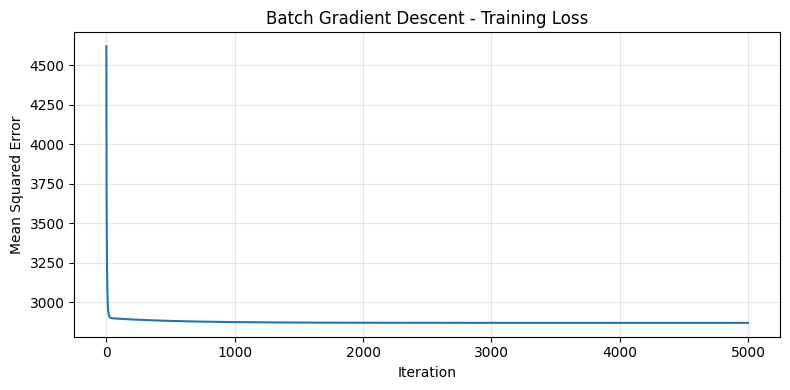

In [19]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.title("Batch Gradient Descent - Training Loss")
plt.xlabel("Iteration")
plt.ylabel("Mean Squared Error")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Effect of learning rate

A small learning rate can take longer to converge. A rate that is too large can make training unstable.

,Learning Rate,Final Training MSE
0,0.001,2899.111
1,0.010,2883.587
2,0.050,2869.332
3,0.100,2868.569


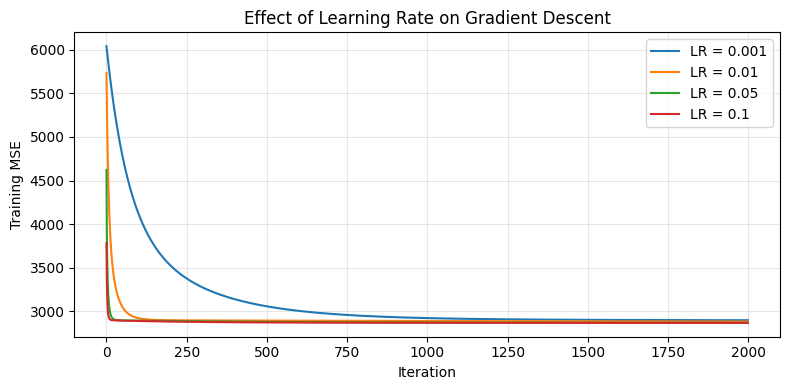

In [20]:
learning_rates = [0.001, 0.01, 0.05, 0.1]
rate_results = []
rate_histories = {}

for rate in learning_rates:
    _, history = batch_gradient_descent(
        X_train_gd, y_train_centered, learning_rate=rate, iterations=2000
    )
    rate_histories[rate] = history
    rate_results.append({"Learning Rate": rate, "Final Training MSE": history[-1]})

display(pd.DataFrame(rate_results).round(3))

plt.figure(figsize=(8, 4))
for rate, history in rate_histories.items():
    plt.plot(history, label=f"LR = {rate}")
plt.title("Effect of Learning Rate on Gradient Descent")
plt.xlabel("Iteration")
plt.ylabel("Training MSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Actual versus predicted values

Points closer to the diagonal line indicate more accurate predictions.

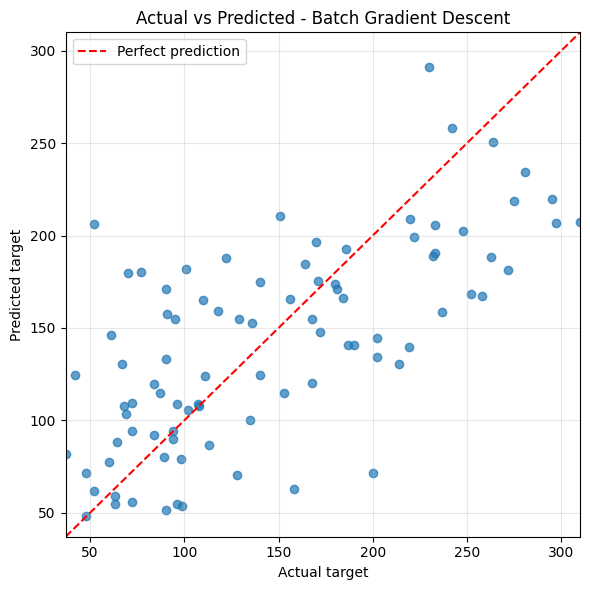

In [21]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, gd_predictions, alpha=0.7)
limits = [min(float(y_test.min()), float(gd_predictions.min())),
          max(float(y_test.max()), float(gd_predictions.max()))]
plt.plot(limits, limits, "r--", label="Perfect prediction")
plt.xlim(limits)
plt.ylim(limits)
plt.xlabel("Actual target")
plt.ylabel("Predicted target")
plt.title("Actual vs Predicted - Batch Gradient Descent")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Final model comparison

All models are evaluated on the same held-out test set. Lower MAE, MSE and RMSE are better; higher R² is better.

In [22]:
comparison = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(comparison.round(3))
best_model = comparison.iloc[0]
print(f"Lowest test RMSE: {best_model['Model']} ({best_model['RMSE']:.2f})")

,Model,MAE,MSE,RMSE,R2 Score
0,Ridge Regression,42.812,2892.015,53.777,0.454
1,Linear Regression (Batch GD),42.795,2899.856,53.850,0.453
2,Linear Regression,42.794,2900.194,53.853,0.453


Lowest test RMSE: Ridge Regression (53.78)


## 12. Result and conclusion

This practical compares Linear Regression, Ridge Regression and a NumPy implementation of Batch Gradient Descent for Linear Regression. MAE, MSE, RMSE and R² are used to evaluate test-set performance.

The loss and learning-rate plots help explain Gradient Descent behaviour. The final conclusion should be based on the metric values generated by running this notebook.

**Note:** This dataset is for education and research. The model is not a medical diagnostic tool.

**Dataset reference:** Scikit-learn Diabetes dataset: https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset